https://docs.langchain.com/oss/python/langchain/streaming

## 1、流式输出的说明
通过 invoke 调用Agent时，内部可能经历多次调用，长时间看不到调用情况，用户体验不好，可以通过 流式调用 （渐进式显示输出）优化用户体验， 实时显示 Agent 运行过程中的更新。特别是在处理LLM 延迟时尤其有效。

流式输出的好处：
- 大模型生成完整响应通常需要几秒钟时间，对于长输出可能达到10-20秒，用户期望即时反馈，流式输出让等待过程更加可控。
- 相比非流式传输需要用户长时间等待完整响应，流式传输可以立即显示文字逐渐出现的效果，大幅降低用户的等待焦虑。

设置方式：

通过`agent.stream(stream_mode=指定模式)`来指定。具体模式有：values、updates（默认）、messages、custom、checkpoints、tasks、debug。

## 2、具体的输出模式

In [15]:
import os
from typing import Dict, Any

from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
from langchain_core.tools import tool
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.config import get_stream_writer
from rich import print as rprint

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL"),
    extra_body={"thinking": {"type": "disabled"}}
)

@tool
def query_customer_data(customer_id: str) -> Dict[str, Any]:
    """
    查询客户基本信息

    Args:
        customer_id: 客户id，唯一标识

    Returns:
         包含客户基本信息的字典
    """
    return {"name": "张三", "level": "Vip", "join_date": "2026-07-01"}

@tool
def check_order_history(customer_id: str) -> Dict[str, Any]:
    """
    查询客户订单历史

    Args:
        customer_id: 客户ID，用于唯一标识客户

    Returns:
        包含客户订单历史的字典，如总订单数、总花费等
    """
    return {"total_orders": 15,"total_spent": 25800.00}

@tool
def get_current_promotions() -> Dict[str, Any]:
    """
    获取当前可用促销活动

    Returns:
        包含当前可用促销活动的字典，如活动名称、有效日期等
    """
    return {"promotions": ["老用户优惠", "会员专属折扣"], "valid_until": "2027-01-30"}

customer_service_agent = create_agent(
    model=model,
    tools=[query_customer_data, check_order_history, get_current_promotions],
    name="customer_service_agent"
)

### 2.1 values输出模式
当stream_mode设置为values模式时，每个步骤执行后，都会输出完整的状态信息，适用于每一步都要获取完整状态、状态持久化场景。

In [ ]:
stream_response = customer_service_agent.stream(
    {"messages": ["查询客户ID为 CUST123456 的个人信息、历史订单和可用优惠"]},
    stream_mode="values"
)

for item in stream_response:
    rprint(item)
    print("-" * 50)

### 2.2 updates输出模式
默认模式。该模式中，每个步骤执行后，只增加更新状态中发生变化的内容，用于监控Agent执行进度，例如观察Agent决定调用工具、工具执行结果等步骤。

In [ ]:
stream_response = customer_service_agent.stream(
    {"messages": ["查询客户ID为 CUST123456 的个人信息、历史订单和可用优惠"]},
    stream_mode="updates"
)

for item in stream_response:
    rprint(item)
    print("-" * 50)

### 2.3 messages输出模式
该模式中会输出流式返回的Token以及相关的元数据（如：来自哪个节点），可以用在实现类似ChatGPT的打字机效果场景，为聊天机器人等交互式应用提供最佳的实时体验。

In [ ]:
stream_response = customer_service_agent.stream(
    {"messages": ["查询客户ID为 CUST123456 的个人信息、历史订单和可用优惠"]},
    stream_mode="messages"
)

for item in stream_response:
    print(item)
    print("-" * 50)

### 2.4 tasks输出模式
该模式会输出当前task任务开始和结束的时间，包含任务的结果和错误信息，该模式用于监控任务的生命周期。

In [ ]:
stream_response = customer_service_agent.stream(
    {"messages": ["查询客户ID为 CUST123456 的个人信息、历史订单和可用优惠"]},
    stream_mode="tasks"
)

for item in stream_response:
    print(item)
    print("-" * 50)

### 2.5 debug输出模式
该模式与tasks模式类似，比tasks模式多输出任务步骤、时间戳、task类型（task/task_result），该模式用于调试、监控task任务的生命周期。

In [ ]:
stream_response = customer_service_agent.stream(
    {"messages": ["查询客户ID为 CUST123456 的个人信息、历史订单和可用优惠"]},
    stream_mode="debug"
)

for item in stream_response:
    rprint(item)
    print("-" * 50)

### 2.6 checkpoints输出模式
该模式中，每当检查点被创建时会触发输出，输出包含检查点中的状态，用于需要状态持久化、工作流恢复或分布式执行跟踪的高级场景。

In [ ]:
checkpointer = InMemorySaver()

customer_service_agent = create_agent(
    model=model,
    tools=[query_customer_data, check_order_history, get_current_promotions],
    name="customer_service_agent",
    checkpointer=checkpointer
)

# 创建唯一的会话id
config = {"configurable": {"thread_id": "session01"}}

checkpoint_count = 0

stream_response = customer_service_agent.stream(
    {"messages": ["查询客户ID为 CUST123456 的个人信息、历史订单和可用优惠"]},
    stream_mode="checkpoints",
    config=config
)

for item in stream_response:
    checkpoint_count += 1
    print(f"检查点 #{checkpoint_count}")
    rprint(item)
    print("-" * 50)

### 2.7 custom输出模式
开发者通过get_stream_writer在工具或节点内部自定义发送的数据，用于输出业务逻辑相关的进度信息（如“已处理10/100条记录”）、自定义日志或指标。

In [ ]:

import time


@tool
def generate_sales_report() -> str:
    """生成销售报告"""
    writer = get_stream_writer()
    writer({"type": "生成销售报告", "message": "开始生成销售报告"})
    # 模拟数据处理
    for i in range(1, 4):
        time.sleep(0.5)
        writer({"type": "生成销售报告", "message": f"生成销售报告进度百分比：{i * 25}%"})
    writer({"type": "生成销售报告", "message": "报告生成完成"})

    return f"销售报告：总收入150万，同比增长12%"

@tool
def generate_inventory_report() -> str:
    """生成库存报告"""
    writer = get_stream_writer()
    writer("开始库存分析...")
    time.sleep(0.5)
    writer("检查当前库存量...")
    time.sleep(0.5)
    writer("生成库存报告...")

    return "当前库存量为10000件，库存充足，无异常"

reporting_agent = create_agent(
    model=model,
    tools=[generate_sales_report, generate_inventory_report],
    name="reporting_agent"
)

stream_response = reporting_agent.stream(
    {"messages": ["生成销售报告和库存报告"]},
    stream_mode="custom",
)

for item in stream_response:
    print(item)
    print("-" * 50)

## 3、流式输出模式总结
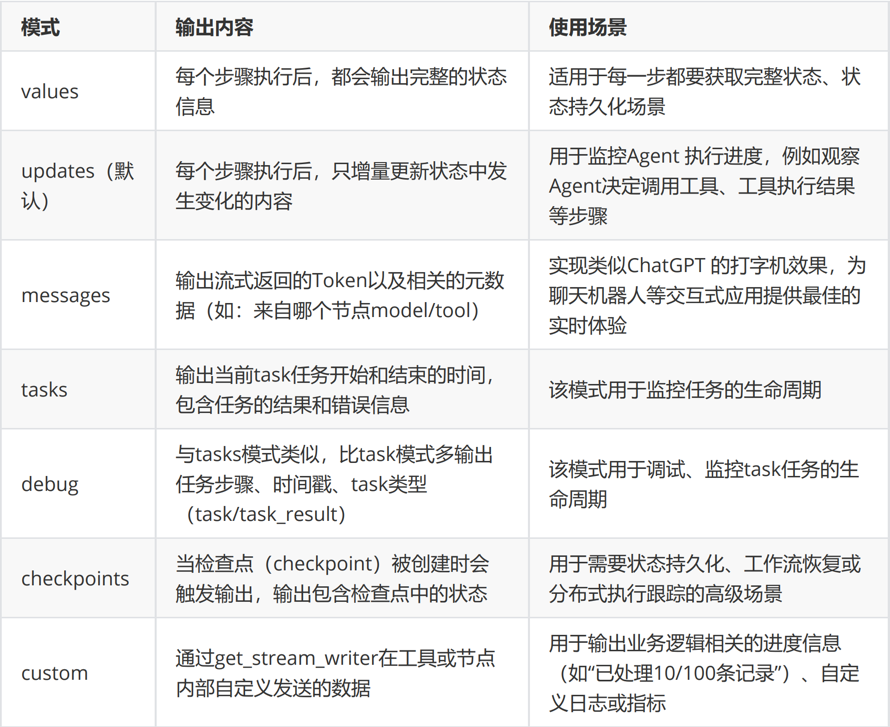

可以根据不同的目标来选择不同的输出模式。例如：
- 实现实时对话交互，优先选择messages模式。
- 观察agent的思考与执行步骤，优先选择updates模式。
- 需要查看每一步状态，优先选择values/tasks/debug模式。
- 在工具执行时输出自定义业务日志优先选择custom模式。

此外，以上这些模式还可以组合使用。例如，可以同时指定stream_mode=["tasks", "updates"]，这样在同一个循环里既能查看Agent task任务执行内容，又能显示Agent每步的更新。

当指定多模式后，可以通过“ for stream_mode, chunk in customer_service_agent.stream... ”来遍历dict，dict的key(stream_mode)是执行模式，value(chunk)是该模式输出的结果。

In [ ]:
stream_response = customer_service_agent.stream(
    {"messages": ["查询客户ID为 CUST123456 的个人信息、历史订单和可用优惠"]},
    stream_mode=["tasks", "updates"]
)

for stream_mode, item in stream_response:
    print(f"当前流模式：{stream_mode}, 当前数据：{item}")
    print("-" * 50)